# Athena autocall : pricing tests

An Athena is an autocallable note of nominal $N$ on the CAC40, with initial fixing $S_{ref}$ and observation dates
$t_1 < \dots < t_n = T$. With $P_k = S_{t_k}/S_{ref}$:
- **autocall**: at the first callable date where $P_k \ge B^{call}_k$, the note is redeemed at $N(1 + c_k)$,
  with $c_k = c\,t_k$ (*snowball*: the coupons accumulate) or $c_k = c\,(t_k - t_{k-1})$ (*fixed* coupon);
- **at maturity**, if never called: $N$ if the capital protection is not knocked-in, otherwise
  $N \max(\text{floor}, \min(1, P_T / K_{put}))$.

The protection is knocked-in if $P_T < B^{prot}$ (*European*) or if the underlying touches $B^{prot} S_{ref}$
at any time before maturity (*American*, continuous with the Brownian bridge, or on a daily grid).

Every form is a parameter of `Athena` (`Produits/products.py`): observation frequency, snowball / fixed coupon,
autocall barrier and step-down, non-call period, protection level and type, airbag ($K_{put} = B^{prot}$),
capital guarantee (floor). The pricer is `Model/monte_carlo.py` under the calibrated Heston model.
The note has a single underlying: worst-of baskets are out of scope.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..", "Model")))   # models, Monte Carlo engine, Greeks
sys.path.append(os.path.abspath(".."))                                # Produits : products.py, market.py, notes_analysis.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston, flat_market
from products import Athena, Phoenix
from monte_carlo import MonteCarloPricer
from greeks import Greeks, bump_vol, bump_carry, plot_greeks_bars, plot_greek_profiles
from notes_analysis import compare_notes, plot_redemption_profiles, plot_call_probabilities, plot_scenarios

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

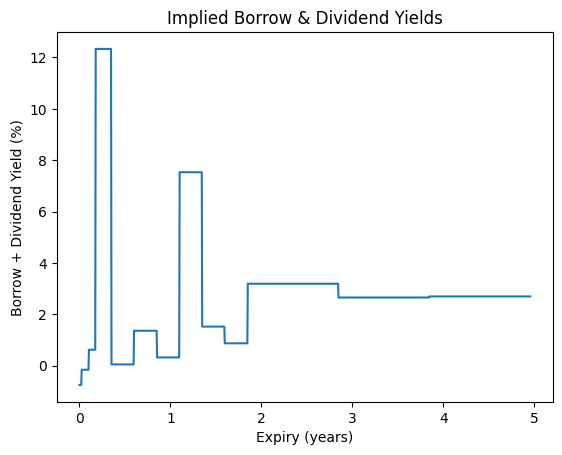

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [2]:
mkt = cac40_heston()
heston, S0 = mkt.heston, mkt.S0
# Weekly grid : observation dates are discrete and the American protection uses the Brownian bridge,
# so a daily grid is only needed for the daily-monitored protection ('american_discrete').
pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=52, seed=42)
daily_pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)

## 1. Mechanics

Redemption at maturity of a note that was never called, for a standard note, an airbag note and capital
guaranteed notes, then simulated scenarios of the base case (4 years, annual observations, autocall at 100%,
snowball coupon of 8% p.a., European protection at 60%).

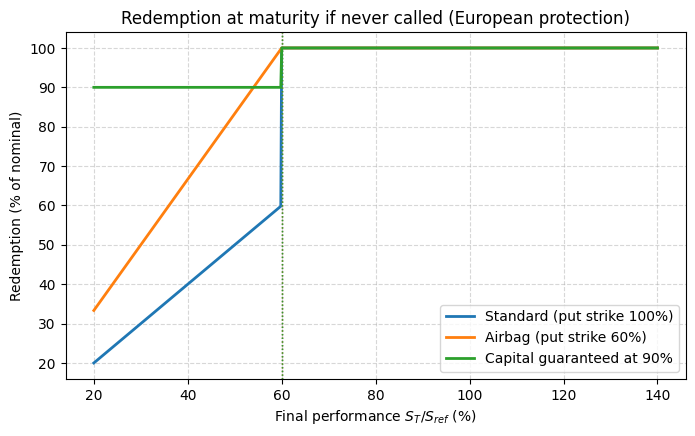

In [3]:
base = Athena(4.0, S0, 0.08, frequency=1.0, autocall_barrier=1.0, protection_barrier=0.6)
plot_redemption_profiles({"Standard (put strike 100%)": base,
                          "Airbag (put strike 60%)": Athena(4.0, S0, 0.08, protection_barrier=0.6, put_strike=0.6),
                          "Capital guaranteed at 90%": Athena(4.0, S0, 0.08, protection_barrier=0.6, floor=0.9)});

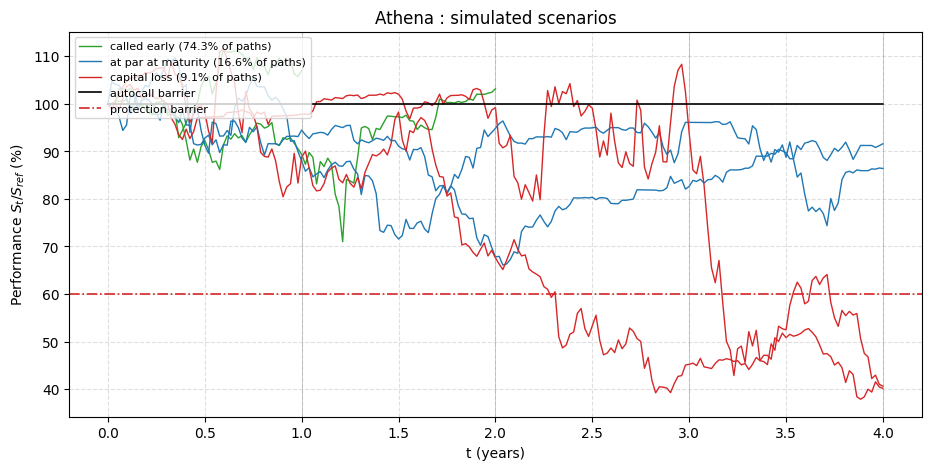

In [4]:
plot_scenarios(pricer, heston, base)

## 2. Validation in a flat Black-Scholes market

No closed form exists for an Athena, but three limit cases have one ($S_0 = S_{ref} = 100$, $r = 3\%$,
$q = 1\%$, $\sigma = 20\%$, $T = 2$, $N = 100$, protection at 60):
1. never called (autocall barrier out of reach), European protection:
   $N D(T) - \frac{N}{S_{ref}}\left[P(B) + (S_{ref} - B)\, DP(B)\right]$, with $P$ a put and $DP$ a cash digital put;
2. never called, American protection: $N D(T) - \frac{N}{S_{ref}}\, PDI(K = S_{ref}, H = B)$ (Reiner-Rubinstein);
3. called for sure at the first date: $N (1 + c\, t_1) D(t_1)$.

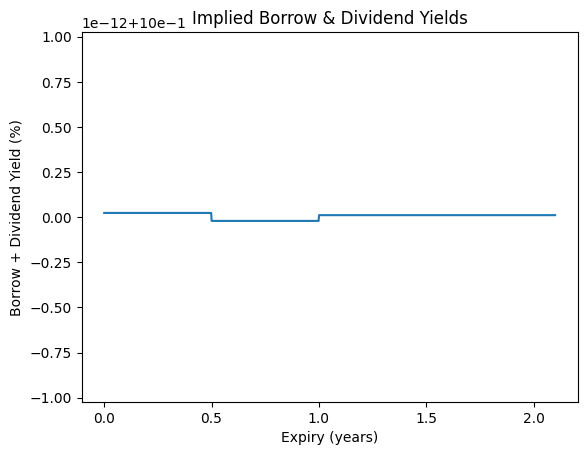

,Closed form,Monte Carlo,Std error,Error / std error
"Never called, European protection",92.6369,92.648,0.0140658,0.792501
"Never called, American protection",91.55,91.5483,0.0219515,-0.0739688
Called for sure at t1 = 0.5,102.452,102.452,0,0


In [5]:
flat = flat_market()
fp = MonteCarloPricer(n_paths=100_000, steps_per_year=52, seed=1)
T, N, B = 2.0, 100.0, 60.0
D = np.exp(-flat.r * T)
put, dput = flat.bs_model.bs_price_vanilla(T, B, flat.sigma, False), flat.bs_model.bs_price_digital(T, B, flat.sigma, False)
cases = {
    "Never called, European protection": (Athena(T, 100.0, 0.0, autocall_barrier=1e6, protection_barrier=0.6),
                                          N * D - N / 100 * (put + (100 - B) * dput)),
    "Never called, American protection": (Athena(T, 100.0, 0.0, autocall_barrier=1e6, protection_barrier=0.6, protection_type="american"),
                                          N * D - N / 100 * flat.bs_model.bs_price_barrier(T, 100.0, B, flat.sigma, False, "down", "in")),
    "Called for sure at t1 = 0.5": (Athena(T, 100.0, 0.08, autocall_barrier=0.0, frequency=0.5),
                                    N * (1 + 0.08 * 0.5) * np.exp(-flat.r * 0.5)),
}
rows = {}
for name, (note, exact) in cases.items():
    res = fp.price(flat.heston, note)
    rows[name] = {"Closed form": exact, "Monte Carlo": res.price, "Std error": res.stderr,
                  "Error / std error": (res.price - exact) / res.stderr if res.stderr > 0 else 0.0}
pd.DataFrame(rows).T

## 3. Base case on the CAC40

Price of the base case, coupon that prices the note at par (no issuer margin), and scenario statistics.

In [6]:
res = pricer.price(heston, base)
print(f"{base}")
print(f"Price : {res.price:.3f} +/- {1.96 * res.stderr:.3f} (95%) for a nominal of 100")
print(f"Fair coupon : {100 * base.fair_coupon(pricer, heston):.3f}% p.a.")
stats = base.statistics(pricer, heston)
pd.Series({k: v for k, v in stats.items() if k != "call probability by date"}, name="Base case").to_frame()

Athena(T=4, 4 obs, coupon 8.00% p.a., autocall 100%, protection 60% european)
Price : 98.596 +/- 0.128 (95%) for a nominal of 100
Fair coupon : 9.412% p.a.


,Base case
probability to reach maturity,0.25704
probability of a capital loss,0.0906
expected loss at maturity (% nominal),5.27305
expected life (years),2.06456
expected number of coupons,0


## 4. All the forms of the Athena

Every variant changes one feature of the base case. *Fair coupon* is the coupon per annum that prices the note at
par: it is the right way to compare structures, since a riskier structure pays a higher coupon.

In [7]:
variants = {
    "Base (annual, snowball, AC 100%, EU 60%)": base,
    "Semi-annual observations":       Athena(4.0, S0, 0.08, frequency=0.5),
    "Quarterly observations":         Athena(4.0, S0, 0.08, frequency=0.25),
    "Monthly observations":           Athena(4.0, S0, 0.08, frequency=1 / 12),
    "Fixed coupon (no snowball)":     Athena(4.0, S0, 0.08, coupon_type="fixed"),
    "Autocall barrier 90%":           Athena(4.0, S0, 0.08, autocall_barrier=0.9),
    "Autocall barrier 110%":          Athena(4.0, S0, 0.08, autocall_barrier=1.1),
    "Step-down 5% per year":          Athena(4.0, S0, 0.08, step_down=0.05),
    "Quarterly, non-call 1 year":     Athena(4.0, S0, 0.08, frequency=0.25, first_call_date=1.0),
    "Protection 50%":                 Athena(4.0, S0, 0.08, protection_barrier=0.5),
    "Protection 70%":                 Athena(4.0, S0, 0.08, protection_barrier=0.7),
    "American protection (continuous)": Athena(4.0, S0, 0.08, protection_type="american"),
    "American protection (daily)":    (Athena(4.0, S0, 0.08, protection_type="american_discrete"), daily_pricer),
    "Airbag":                         Athena(4.0, S0, 0.08, put_strike=0.6),
    "Capital guaranteed 90%":         Athena(4.0, S0, 0.08, floor=0.9),
    "Capital guaranteed 100%":        Athena(4.0, S0, 0.08, floor=1.0),
}
start = time.time()
athena_variants = compare_notes(pricer, heston, variants)
print(f"{time.time() - start:.1f}s")
athena_variants

3.4s


,Coupon p.a. (%),Price,Std error,Fair coupon p.a. (%),P(call at 1st date) (%),P(reach maturity) (%),P(capital loss) (%),Expected loss (%),Expected life (y),Expected coupons,Time (s)
"Base (annual, snowball, AC 100%, EU 60%)",8,98.5955,0.0654466,9.41201,55.692,25.704,9.06,5.27305,2.06456,0,0.0201037
Semi-annual observations,8,98.6356,0.0632588,9.92822,53.298,18.61,6.972,4.07502,1.47667,0,0.0249228
Quarterly observations,8,98.7669,0.0585111,10.5382,55.428,13.29,5.218,3.05192,1.03247,0,0.0367591
Monthly observations,8,99.1605,0.0484354,11.1144,56.21,7.766,3.128,1.83039,0.588053,0,0.0836692
Fixed coupon (no snowball),8,96.3974,0.0576021,13.0044,55.692,25.704,9.06,5.27305,2.06456,0,0.0179453
Autocall barrier 90%,8,100.951,0.0616269,7.02856,77.372,13.236,6.41,3.774,1.5403,0,0.0179098
Autocall barrier 110%,8,95.4015,0.0638175,12.7125,25.068,45.604,11.766,6.76619,2.85438,0,0.0182266
Step-down 5% per year,8,100.647,0.066348,7.45593,55.692,17.564,8.574,5.01456,1.9465,0,0.0184844
"Quarterly, non-call 1 year",8,99.0869,0.0639924,8.94384,0,22.064,8.416,4.91549,1.88512,0,0.0351362
Protection 50%,8,99.9037,0.0603815,8.09683,55.692,25.704,5.912,3.85866,2.06456,0,0.0186446


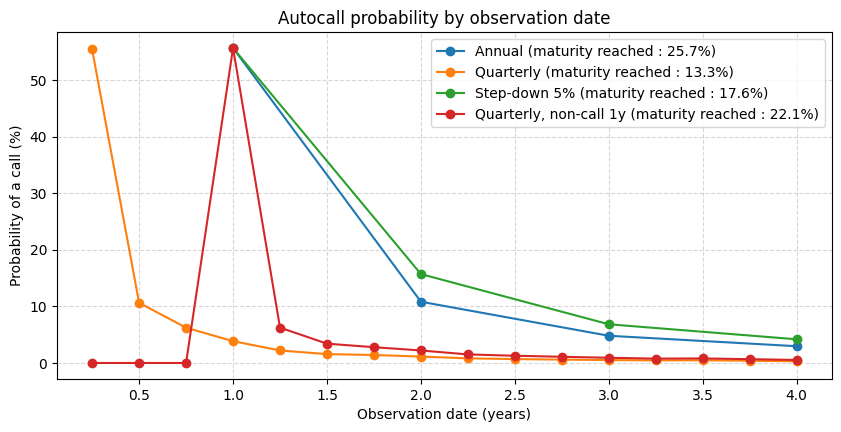

In [8]:
plot_call_probabilities(pricer, heston, {"Annual": base, "Quarterly": variants["Quarterly observations"],
                                         "Step-down 5%": variants["Step-down 5% per year"],
                                         "Quarterly, non-call 1y": variants["Quarterly, non-call 1 year"]})

## 5. Fair coupon as a function of the barriers

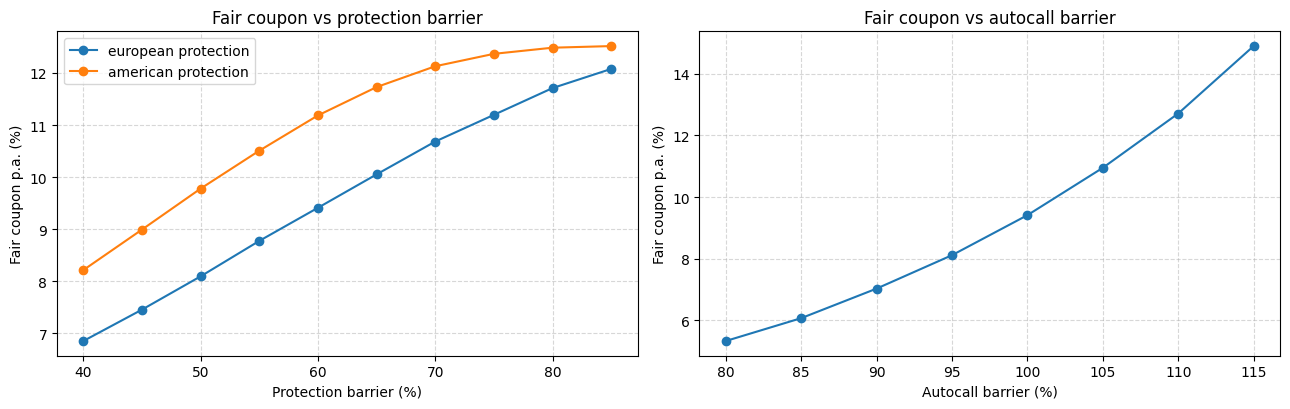

In [9]:
protections = np.arange(0.40, 0.851, 0.05)
autocall_levels = np.arange(0.80, 1.151, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for kind in ["european", "american"]:
    axes[0].plot(100 * protections, [100 * Athena(4.0, S0, 0.08, protection_barrier=b, protection_type=kind).fair_coupon(pricer, heston)
                                     for b in protections], "o-", label=f"{kind} protection")
axes[1].plot(100 * autocall_levels, [100 * Athena(4.0, S0, 0.08, autocall_barrier=b).fair_coupon(pricer, heston)
                                     for b in autocall_levels], "o-")
axes[0].set_xlabel("Protection barrier (%)"); axes[1].set_xlabel("Autocall barrier (%)")
for ax, title in zip(axes, ["Fair coupon vs protection barrier", "Fair coupon vs autocall barrier"]):
    ax.set_ylabel("Fair coupon p.a. (%)"); ax.set_title(title); ax.grid(True, linestyle="--", alpha=0.5)
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. Greeks

Bump and revalue with common random numbers (`Model/greeks.py`), on a nominal of 100. The initial fixing $S_{ref}$
is kept fixed: only the market moves. Units: Delta per index point (multiply by $S_0/100 \approx 80$ for a 1% move),
Gamma per index point squared, Vega and Volga per vol point, Vanna as Delta change per vol point, Rho per +1% of
rates, Dividend per +1% of borrow + dividend yield, Theta per calendar day.

In [10]:
greeks = Greeks(pricer)
notes = [base, variants["American protection (continuous)"], variants["Step-down 5% per year"], variants["Airbag"],
         variants["Capital guaranteed 90%"]]
labels = ["Base", "American protection", "Step-down 5%", "Airbag", "Guaranteed 90%"]
start = time.time()
athena_greeks = greeks.table(heston, notes, greeks=Greeks.ORDER, with_stderr=True, labels=labels)
print(f"{time.time() - start:.1f}s")
athena_greeks[[c for c in athena_greeks.columns if not c.endswith("stderr")]]

26.0s


,price,delta,gamma,vega,vanna,volga,rho,dividend,theta
Base,98.5955,0.0050573,-2.98462e-06,-0.548608,0.000251333,-0.0423108,-0.769685,-1.1152,0.00496203
American protection,96.8326,0.00644031,-6.55021e-06,-0.656818,0.000197075,-0.0378116,-0.545526,-1.26855,0.00501438
Step-down 5%,100.647,0.00321283,-3.99306e-06,-0.636741,0.000636433,-0.052164,-0.899606,-0.93511,0.0079326
Airbag,100.894,0.00343492,-3.11259e-06,-0.354426,0.000128135,-0.0408408,-1.16147,-0.815068,0.0036939
Guaranteed 90%,102.563,0.00240537,-3.99948e-06,-0.139165,4.40537e-05,-0.0277298,-1.43572,-0.607636,0.00232289


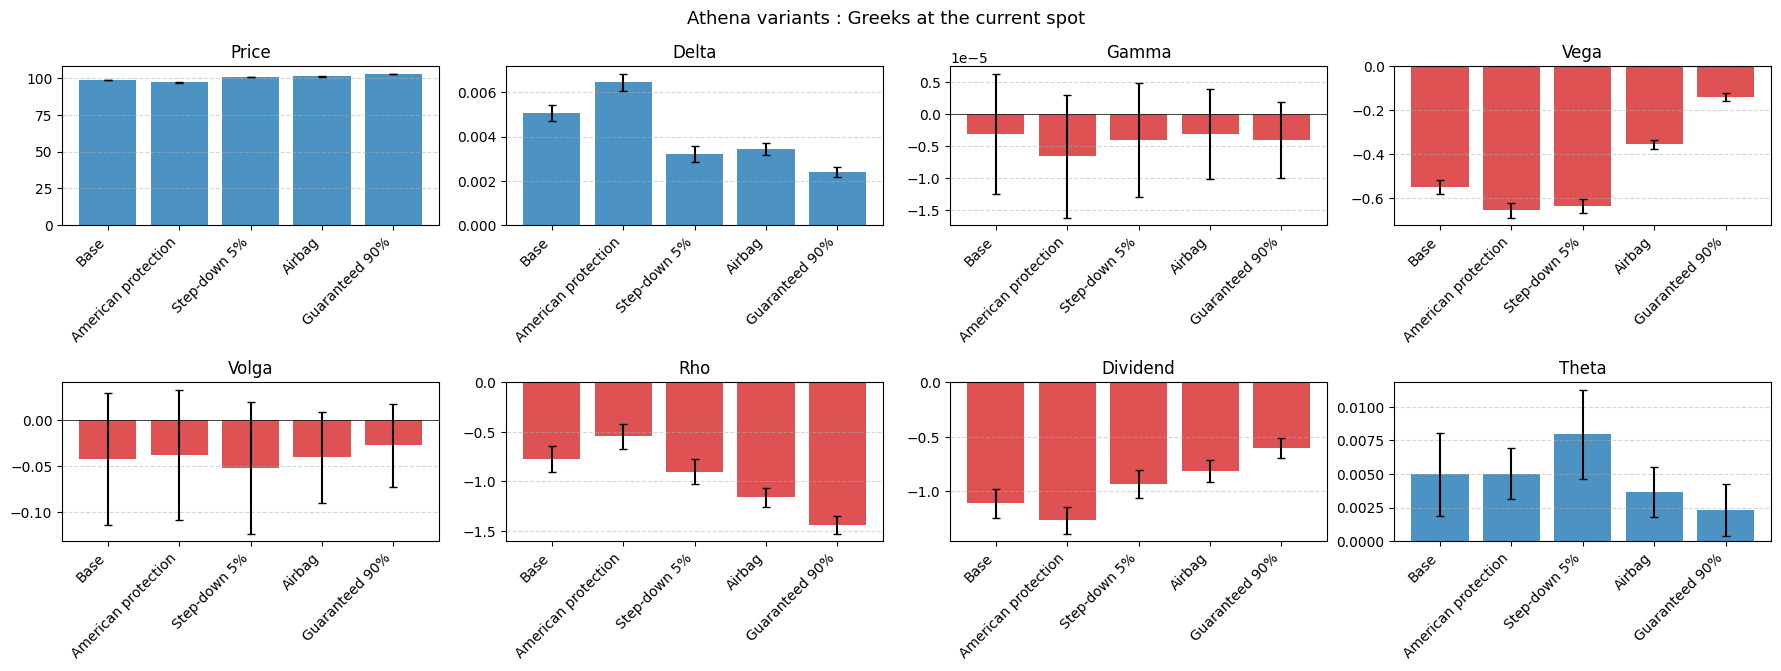

In [11]:
plot_greeks_bars(athena_greeks, greeks=("price", "delta", "gamma", "vega", "volga", "rho", "dividend", "theta"),
                 title="Athena variants : Greeks at the current spot");

Greeks as functions of the spot (the initial fixing stays at 8042): the note is long the underlying, and its Delta
increases as the spot falls towards the protection barrier, where the short down-and-in put becomes active (with an
American protection, the Delta peaks just above the barrier). Its Vega is negative over most of the range: the
holder is short volatility through the put.

41.2s


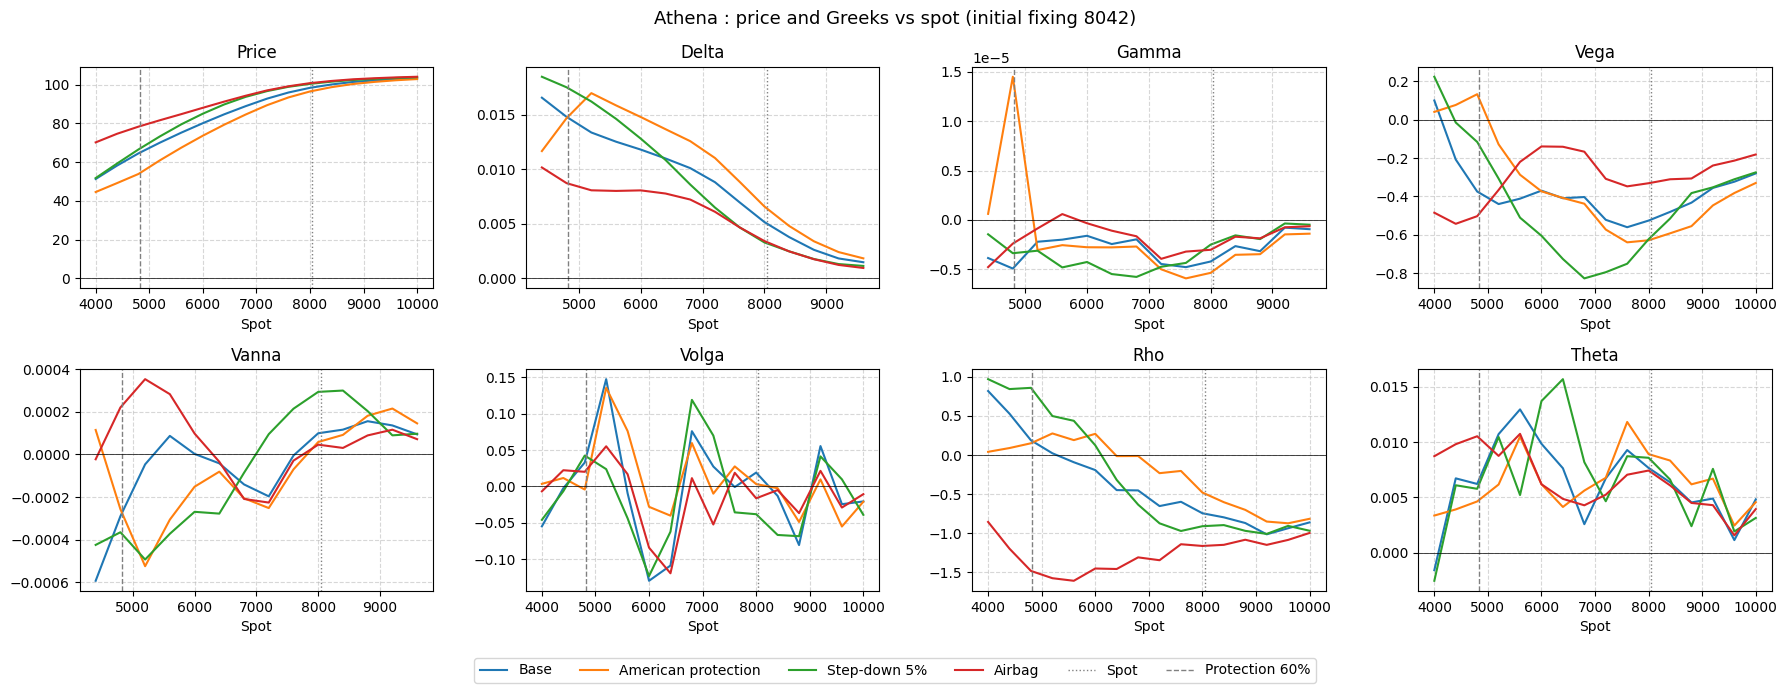

In [12]:
profile_pricer = MonteCarloPricer(n_paths=30_000, steps_per_year=52, seed=42)
spots = np.arange(4000.0, 10001.0, 400.0)
start = time.time()
athena_profiles = Greeks(profile_pricer).profiles(heston, notes[:4], spots, labels=labels[:4])
print(f"{time.time() - start:.1f}s")
plot_greek_profiles(athena_profiles, vlines={"Spot": S0, "Protection 60%": 0.6 * S0},
                    title="Athena : price and Greeks vs spot (initial fixing 8042)");

## 7. Sensitivities to the Heston parameters

In [13]:
pd.concat({label: greeks.parameter_sensitivities(heston, note)["value"] for label, note in zip(labels[:4], notes[:4])}, axis=1)

,Base,American protection,Step-down 5%,Airbag
d/dv0,-69.9013,-75.2302,-56.5126,-52.0123
d/dtheta,-69.3824,-101.212,-101.352,-48.3723
d/dkappa,-0.810676,-1.54687,-1.34213,-0.296786
d/dxi,3.93723,5.81743,2.87465,2.0284
d/drho,-1.02757,-0.926094,-0.0399793,-0.454152


## 8. Limitations

- Single underlying: worst-of / basket Athena notes need a multi-asset model.
- The fair coupon prices the note at par without issuer margin nor funding / credit spread.
- Euler scheme for the variance (Feller condition violated), Brownian bridge with the variance frozen over each
  week for the continuous protection; the daily-monitored protection is checked on a daily grid.
- Beyond the last listed expiry (4.86 years), the forward curve is extrapolated with a flat carry.